In [1]:
!pip -q install lightgbm xgboost shap PyALE kaggle


In [6]:
import os
import pandas as pd

# We will use the synthetic CSV file you uploaded directly!
csv_path = "/content/home_credit_synthetic_35000.csv"

if os.path.exists(csv_path):
    df = pd.read_csv(csv_path)
    print(f"Successfully loaded the dataset directly from: {csv_path}")
    print(f"Dataset Shape: {df.shape}")
    print("\nFirst 5 rows:")
    display(df.head())
else:
    print(f"[ERROR] Could not find '{csv_path}'. Please make sure it is uploaded to your /content/ folder.")

Successfully loaded the dataset directly from: /content/home_credit_synthetic_35000.csv
Dataset Shape: (35000, 35)

First 5 rows:


,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,NAME_FAMILY_STATUS,CNT_FAM_MEMBERS,NAME_EDUCATION_TYPE,...,BUREAU_OVERDUE_COUNT,PREV_APP_COUNT,PREV_REFUSED_COUNT,INSTAL_LATE_PAYMENT_RATIO,DAYS_LAST_PHONE_CHANGE,AMT_REQ_CREDIT_BUREAU_YEAR,AGE_YEARS,CREDIT_INCOME_RATIO,ANNUITY_INCOME_RATIO,CREDIT_TERM
0,100001,1,Cash loans,F,Y,N,0,Single / not married,1,Higher education,...,1,6,1,0.339,-827,4,46.8,6.637,0.1438,0.0217
1,100002,0,Cash loans,F,Y,N,1,Single / not married,2,Higher education,...,0,4,1,0.022,-3978,0,39.0,4.243,0.1096,0.0258
2,100003,0,Cash loans,F,N,Y,0,Married,2,Secondary / secondary special,...,1,0,0,0.207,-852,4,45.2,8.815,0.1910,0.0217
3,100004,0,Cash loans,M,Y,Y,2,Civil marriage,4,Secondary / secondary special,...,1,1,0,0.031,-1574,2,56.8,4.620,0.1194,0.0258
4,100005,0,Cash loans,F,Y,N,1,Married,3,Secondary / secondary special,...,0,3,0,0.000,-365,1,21.0,2.525,0.1178,0.0467


In [7]:
import os
import gc
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.base import clone

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier

from sklearn.metrics import (
    roc_auc_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    brier_score_loss,
    log_loss,
    confusion_matrix,
    classification_report,
    RocCurveDisplay,
    PrecisionRecallDisplay
)

from sklearn.inspection import (
    permutation_importance,
    PartialDependenceDisplay
)

from lightgbm import LGBMClassifier, early_stopping, log_evaluation
from xgboost import XGBClassifier

import shap

from IPython.display import display

DATA_PATH = "/content/home_credit"

RANDOM_STATE = 42

print("Libraries imported successfully")

Libraries imported successfully


In [9]:
# Since we are using the synthetic dataset, let's split the loaded 'df' into train and test sets!
# This replaces reading the non-existent Kaggle CSV files.

train, test = train_test_split(df, test_size=0.2, random_state=RANDOM_STATE, stratify=df["TARGET"])

print("Training shape:", train.shape)
print("Testing shape:", test.shape)

print("\nTarget distribution in Training Set:")
print(train["TARGET"].value_counts())

print("\nTarget percentages in Training Set:")
print(train["TARGET"].value_counts(normalize=True) * 100)

display(train.head())

Training shape: (28000, 35)
Testing shape: (7000, 35)

Target distribution in Training Set:
TARGET
0    25435
1     2565
Name: count, dtype: int64

Target percentages in Training Set:
TARGET
0    90.839286
1     9.160714
Name: proportion, dtype: float64


,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,NAME_FAMILY_STATUS,CNT_FAM_MEMBERS,NAME_EDUCATION_TYPE,...,BUREAU_OVERDUE_COUNT,PREV_APP_COUNT,PREV_REFUSED_COUNT,INSTAL_LATE_PAYMENT_RATIO,DAYS_LAST_PHONE_CHANGE,AMT_REQ_CREDIT_BUREAU_YEAR,AGE_YEARS,CREDIT_INCOME_RATIO,ANNUITY_INCOME_RATIO,CREDIT_TERM
7117,107118,0,Cash loans,M,N,Y,0,Married,2,Higher education,...,1,4,1,0.100,-114,4,23.4,1.703,0.0369,0.0217
24767,124768,0,Revolving loans,F,N,Y,1,Separated,2,Secondary / secondary special,...,1,2,0,0.112,-652,1,43.9,3.933,0.3474,0.0883
14966,114967,1,Cash loans,F,N,Y,1,Married,3,Secondary / secondary special,...,0,1,0,0.142,-2255,1,41.3,11.487,0.3765,0.0328
32107,132108,0,Cash loans,F,N,N,0,Separated,1,Secondary / secondary special,...,0,9,3,0.110,-92,1,40.9,3.943,0.0854,0.0217
17733,117734,0,Cash loans,M,N,Y,2,Married,4,Secondary / secondary special,...,0,5,1,0.056,-387,3,34.1,2.767,0.1291,0.0467


In [11]:
def aggregate_customer_data(df, prefix, excluded_ids=None):

    df = df.copy()

    excluded_ids = excluded_ids or []

    numeric_cols = [
        col for col in df.select_dtypes(include=np.number).columns
        if col not in ["SK_ID_CURR"] + excluded_ids
    ]

    categorical_cols = [
        col for col in df.select_dtypes(exclude=np.number).columns
        if col != "SK_ID_CURR"
    ]

    result = None

    if numeric_cols:

        agg_dict = {
            col: ["mean", "max", "min", "sum", "std"]
            for col in numeric_cols
        }

        result = df.groupby("SK_ID_CURR").agg(agg_dict)

        result.columns = [
            f"{prefix}_{col}_{stat}".upper()
            for col, stat in result.columns
        ]

    if categorical_cols:

        cat_result = df.groupby("SK_ID_CURR")[categorical_cols].nunique()

        cat_result.columns = [
            f"{prefix}_{col}_NUNIQUE".upper()
            for col in categorical_cols
        ]

        if result is None:
            result = cat_result
        else:
            result = result.join(cat_result)

    if result is None:
        return None

    return result.reset_index()

In [12]:
bureau_path = f"{DATA_PATH}/bureau.csv"
bb_path = f"{DATA_PATH}/bureau_balance.csv"

if os.path.exists(bureau_path):

    bureau = pd.read_csv(bureau_path)

    if os.path.exists(bb_path):

        bb = pd.read_csv(bb_path)

        bb["STATUS"] = bb["STATUS"].astype(str)

        bb_num = bb.groupby("SK_ID_BUREAU").agg({
            "MONTHS_BALANCE": ["min", "max", "count"],
            "STATUS": "nunique"
        })

        bb_num.columns = [
            "BB_MONTH_MIN",
            "BB_MONTH_MAX",
            "BB_MONTH_COUNT",
            "BB_STATUS_NUNIQUE"
        ]

        bb_status = pd.crosstab(
            bb["SK_ID_BUREAU"],
            bb["STATUS"]
        )

        bb_status.columns = [
            f"BB_STATUS_{c}_COUNT"
            for c in bb_status.columns
        ]

        bb_agg = bb_num.join(bb_status).reset_index()

        bureau = bureau.merge(
            bb_agg,
            on="SK_ID_BUREAU",
            how="left"
        )

        del bb, bb_num, bb_status, bb_agg
        gc.collect()

    bureau_agg = aggregate_customer_data(
        bureau,
        "BUREAU",
        excluded_ids=["SK_ID_BUREAU"]
    )

    if bureau_agg is not None:

        train = train.merge(
            bureau_agg,
            on="SK_ID_CURR",
            how="left"
        )

        test = test.merge(
            bureau_agg,
            on="SK_ID_CURR",
            how="left"
        )

    del bureau
    gc.collect()

    print("Bureau features added")

In [13]:
previous_path = f"{DATA_PATH}/previous_application.csv"

if os.path.exists(previous_path):

    previous = pd.read_csv(previous_path)

    previous_agg = aggregate_customer_data(
        previous,
        "PREVIOUS",
        excluded_ids=["SK_ID_PREV"]
    )

    train = train.merge(
        previous_agg,
        on="SK_ID_CURR",
        how="left"
    )

    test = test.merge(
        previous_agg,
        on="SK_ID_CURR",
        how="left"
    )

    del previous, previous_agg
    gc.collect()

    print("Previous application features added")

In [14]:
historical_files = {
    "installments_payments.csv": "INSTALLMENTS",
    "POS_CASH_balance.csv": "POS",
    "credit_card_balance.csv": "CREDIT_CARD"
}

for filename, prefix in historical_files.items():

    path = f"{DATA_PATH}/{filename}"

    if not os.path.exists(path):
        print("Skipping:", filename)
        continue

    df = pd.read_csv(path)

    excluded = [
        col for col in df.columns
        if col.startswith("SK_ID_") and col != "SK_ID_CURR"
    ]

    aggregated = aggregate_customer_data(
        df,
        prefix,
        excluded_ids=excluded
    )

    if aggregated is not None:

        train = train.merge(
            aggregated,
            on="SK_ID_CURR",
            how="left"
        )

        test = test.merge(
            aggregated,
            on="SK_ID_CURR",
            how="left"
        )

    del df, aggregated
    gc.collect()

    print(prefix, "features added")

print("Final training shape:", train.shape)
print("Final testing shape:", test.shape)

Skipping: installments_payments.csv
Skipping: POS_CASH_balance.csv
Skipping: credit_card_balance.csv
Final training shape: (28000, 35)
Final testing shape: (7000, 35)


In [15]:
historical_files = {
    "installments_payments.csv": "INSTALLMENTS",
    "POS_CASH_balance.csv": "POS",
    "credit_card_balance.csv": "CREDIT_CARD"
}

for filename, prefix in historical_files.items():

    path = f"{DATA_PATH}/{filename}"

    if not os.path.exists(path):
        print("Skipping:", filename)
        continue

    df = pd.read_csv(path)

    excluded = [
        col for col in df.columns
        if col.startswith("SK_ID_") and col != "SK_ID_CURR"
    ]

    aggregated = aggregate_customer_data(
        df,
        prefix,
        excluded_ids=excluded
    )

    if aggregated is not None:

        train = train.merge(
            aggregated,
            on="SK_ID_CURR",
            how="left"
        )

        test = test.merge(
            aggregated,
            on="SK_ID_CURR",
            how="left"
        )

    del df, aggregated
    gc.collect()

    print(prefix, "features added")

print("Final training shape:", train.shape)
print("Final testing shape:", test.shape)

Skipping: installments_payments.csv
Skipping: POS_CASH_balance.csv
Skipping: credit_card_balance.csv
Final training shape: (28000, 35)
Final testing shape: (7000, 35)


In [16]:
def create_features(df):

    df = df.copy()

    if {"AMT_CREDIT", "AMT_ANNUITY"}.issubset(df.columns):
        df["CREDIT_ANNUITY_RATIO"] = (
            df["AMT_CREDIT"] /
            (df["AMT_ANNUITY"] + 1)
        )

    if {"AMT_CREDIT", "AMT_GOODS_PRICE"}.issubset(df.columns):
        df["CREDIT_GOODS_RATIO"] = (
            df["AMT_CREDIT"] /
            (df["AMT_GOODS_PRICE"] + 1)
        )

    if {"AMT_INCOME_TOTAL", "AMT_ANNUITY"}.issubset(df.columns):
        df["ANNUITY_INCOME_RATIO"] = (
            df["AMT_ANNUITY"] /
            (df["AMT_INCOME_TOTAL"] + 1)
        )

    if {"AMT_CREDIT", "AMT_INCOME_TOTAL"}.issubset(df.columns):
        df["CREDIT_INCOME_RATIO"] = (
            df["AMT_CREDIT"] /
            (df["AMT_INCOME_TOTAL"] + 1)
        )

    if {"AMT_INCOME_TOTAL", "CNT_FAM_MEMBERS"}.issubset(df.columns):
        df["INCOME_PER_FAMILY_MEMBER"] = (
            df["AMT_INCOME_TOTAL"] /
            (df["CNT_FAM_MEMBERS"] + 1)
        )

    if {"DAYS_EMPLOYED", "DAYS_BIRTH"}.issubset(df.columns):
        df["EMPLOYMENT_AGE_RATIO"] = (
            df["DAYS_EMPLOYED"].abs() /
            (df["DAYS_BIRTH"].abs() + 1)
        )

    return df


train = create_features(train)
test = create_features(test)

print("Feature engineering completed")

Feature engineering completed


In [17]:
TARGET = "TARGET"
ID = "SK_ID_CURR"

X = train.drop(
    columns=[TARGET, ID]
)

y = train[TARGET].astype(int)

X_test = test.drop(
    columns=[ID]
)

X_test = X_test.reindex(
    columns=X.columns
)

X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)

Training: (22400, 37)
Validation: (5600, 37)
Test: (7000, 37)


In [18]:
numeric_features = X_train.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = X_train.select_dtypes(
    exclude=np.number
).columns.tolist()

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(
        strategy="median",
        keep_empty_features=True
    ))
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(
        strategy="most_frequent",
        keep_empty_features=True
    )),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        min_frequency=20,
        sparse_output=True,
        dtype=np.float32
    ))
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features)
])

X_train_processed = preprocessor.fit_transform(X_train)

X_val_processed = preprocessor.transform(X_val)

print("Processed training shape:", X_train_processed.shape)
print("Processed validation shape:", X_val_processed.shape)

Processed training shape: (22400, 68)
Processed validation shape: (5600, 68)


In [19]:
decision_tree = DecisionTreeClassifier(
    max_depth=6,
    min_samples_leaf=500,
    criterion="gini",
    random_state=RANDOM_STATE
)

decision_tree.fit(
    X_train_processed,
    y_train
)

print("Decision Tree trained")

Decision Tree trained


In [20]:
random_forest = RandomForestClassifier(
    n_estimators=250,
    max_depth=18,
    min_samples_leaf=100,
    max_features="sqrt",
    n_jobs=-1,
    random_state=RANDOM_STATE
)

random_forest.fit(
    X_train_processed,
    y_train
)

print("Random Forest trained")

Random Forest trained


In [21]:
lightgbm_model = LGBMClassifier(
    objective="binary",
    n_estimators=2000,
    learning_rate=0.03,
    num_leaves=31,
    max_depth=-1,
    min_child_samples=100,
    subsample=0.8,
    subsample_freq=1,
    colsample_bytree=0.8,
    reg_alpha=0.1,
    reg_lambda=5,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    verbosity=-1
)

lightgbm_model.fit(
    X_train_processed,
    y_train,
    eval_set=[(X_val_processed, y_val)],
    eval_metric="auc",
    callbacks=[
        early_stopping(100),
        log_evaluation(200)
    ]
)

print("LightGBM trained")

Training until validation scores don't improve for 100 rounds
[200]	valid_0's auc: 0.905856	valid_0's binary_logloss: 0.19063
Early stopping, best iteration is:
[122]	valid_0's auc: 0.906893	valid_0's binary_logloss: 0.191512
LightGBM trained


In [22]:
xgboost_model = XGBClassifier(
    n_estimators=1500,
    max_depth=5,
    learning_rate=0.03,
    min_child_weight=50,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_alpha=0.1,
    reg_lambda=5,
    objective="binary:logistic",
    eval_metric="auc",
    tree_method="hist",
    early_stopping_rounds=100,
    random_state=RANDOM_STATE,
    n_jobs=-1
)

xgboost_model.fit(
    X_train_processed,
    y_train,
    eval_set=[(X_val_processed, y_val)],
    verbose=200
)

print("XGBoost trained")

[0]	validation_0-auc:0.85702
[200]	validation_0-auc:0.90608
[315]	validation_0-auc:0.90547
XGBoost trained


In [23]:
from sklearn.decomposition import TruncatedSVD

svd_components = min(
    100,
    X_train_processed.shape[1] - 1
)

svd = TruncatedSVD(
    n_components=svd_components,
    random_state=RANDOM_STATE
)

X_train_svd = svd.fit_transform(X_train_processed)
X_val_svd = svd.transform(X_val_processed)

scaler = StandardScaler()

X_train_svd = scaler.fit_transform(X_train_svd)
X_val_svd = scaler.transform(X_val_svd)

neural_network = MLPClassifier(
    hidden_layer_sizes=(128, 64, 32),
    activation="relu",
    solver="adam",
    alpha=0.001,
    learning_rate_init=0.001,
    max_iter=150,
    early_stopping=True,
    validation_fraction=0.1,
    random_state=RANDOM_STATE
)

neural_network.fit(
    X_train_svd,
    y_train
)

print("Neural Network trained")

Neural Network trained


In [24]:
logistic_model = LogisticRegression(
    max_iter=1000,
    solver="saga",
    C=0.5,
    n_jobs=-1,
    random_state=RANDOM_STATE
)

logistic_model.fit(
    X_train_processed,
    y_train
)

print("Logistic Regression trained")

Logistic Regression trained


In [25]:
models = {
    "Logistic Regression": logistic_model,
    "Decision Tree": decision_tree,
    "Random Forest": random_forest,
    "LightGBM": lightgbm_model,
    "XGBoost": xgboost_model
}

predictions = {}

for name, model in models.items():

    predictions[name] = model.predict_proba(
        X_val_processed
    )[:, 1]

predictions["Neural Network"] = (
    neural_network.predict_proba(X_val_svd)[:, 1]
)

In [26]:
results = []

for name, pred in predictions.items():

    pred_class = (pred >= 0.5).astype(int)

    results.append({

        "Model": name,

        "ROC_AUC": roc_auc_score(y_val, pred),

        "PR_AUC": average_precision_score(y_val, pred),

        "Accuracy": accuracy_score(
            y_val,
            pred_class
        ),

        "Precision": precision_score(
            y_val,
            pred_class,
            zero_division=0
        ),

        "Recall": recall_score(
            y_val,
            pred_class,
            zero_division=0
        ),

        "F1_Score": f1_score(
            y_val,
            pred_class,
            zero_division=0
        ),

        "Brier_Score": brier_score_loss(
            y_val,
            pred
        ),

        "Log_Loss": log_loss(
            y_val,
            pred
        )
    })

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="ROC_AUC",
    ascending=False
).reset_index(drop=True)

display(
    results_df.style.format({
        col: "{:.4f}"
        for col in results_df.select_dtypes(
            include=np.number
        ).columns
    })
)

,Model,ROC_AUC,PR_AUC,Accuracy,Precision,Recall,F1_Score,Brier_Score,Log_Loss
0,LightGBM,0.9069,0.5822,0.9259,0.7025,0.3314,0.4503,0.0553,0.1915
1,XGBoost,0.9064,0.5745,0.9254,0.6792,0.3509,0.4627,0.0557,0.1914
2,Random Forest,0.8965,0.5487,0.9111,0.8947,0.0331,0.0639,0.0618,0.2122
3,Neural Network,0.8741,0.5337,0.9223,0.6413,0.3450,0.4487,0.0600,0.2169
4,Decision Tree,0.8666,0.3852,0.9129,0.5767,0.1832,0.2781,0.0651,0.2207
5,Logistic Regression,0.7613,0.3501,0.9143,0.6542,0.1365,0.2258,0.0715,0.2626


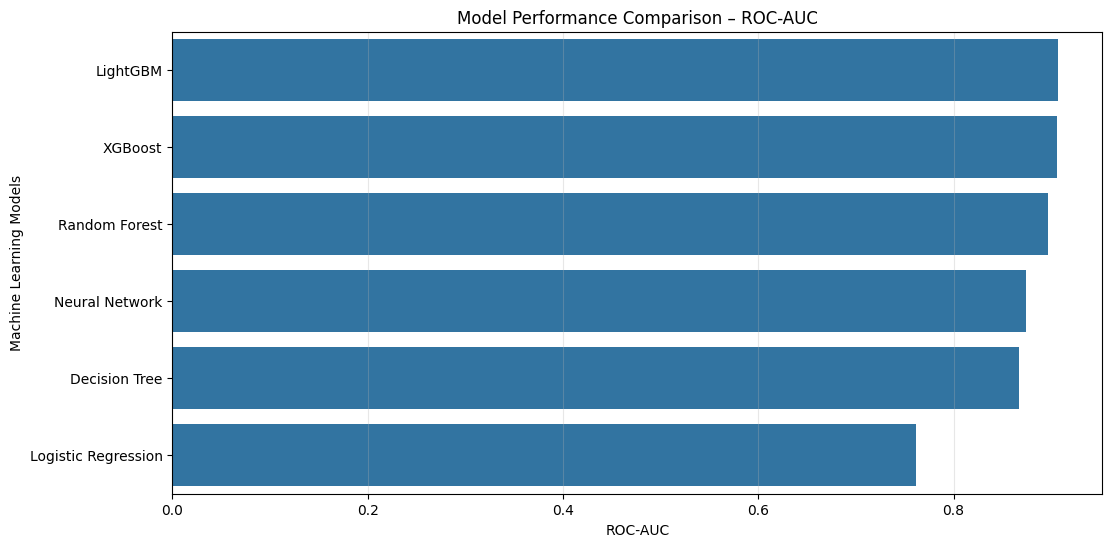

In [27]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=results_df,
    x="ROC_AUC",
    y="Model"
)

plt.title("Model Performance Comparison – ROC-AUC")
plt.xlabel("ROC-AUC")
plt.ylabel("Machine Learning Models")
plt.grid(axis="x", alpha=0.3)

plt.show()

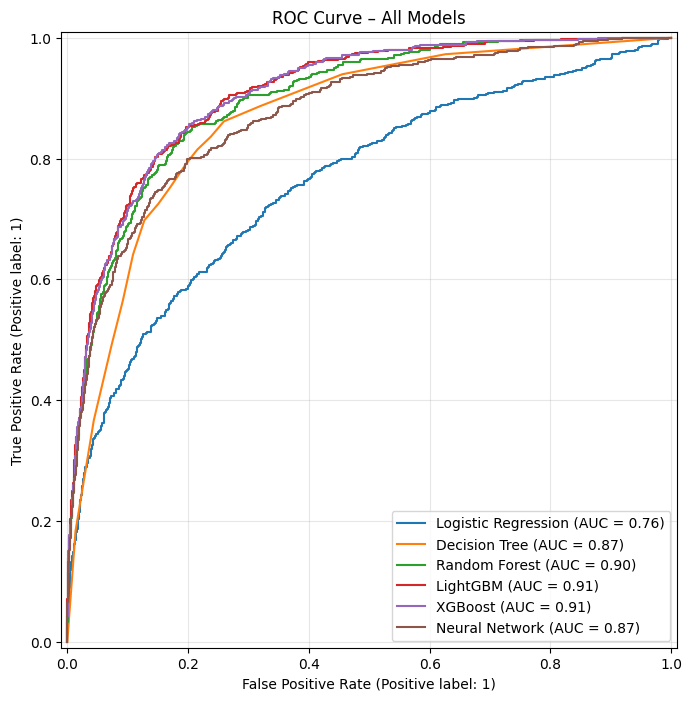

In [28]:
plt.figure(figsize=(10, 8))

for name, pred in predictions.items():

    RocCurveDisplay.from_predictions(
        y_val,
        pred,
        name=name,
        ax=plt.gca()
    )

plt.title("ROC Curve – All Models")
plt.grid(alpha=0.3)
plt.show()

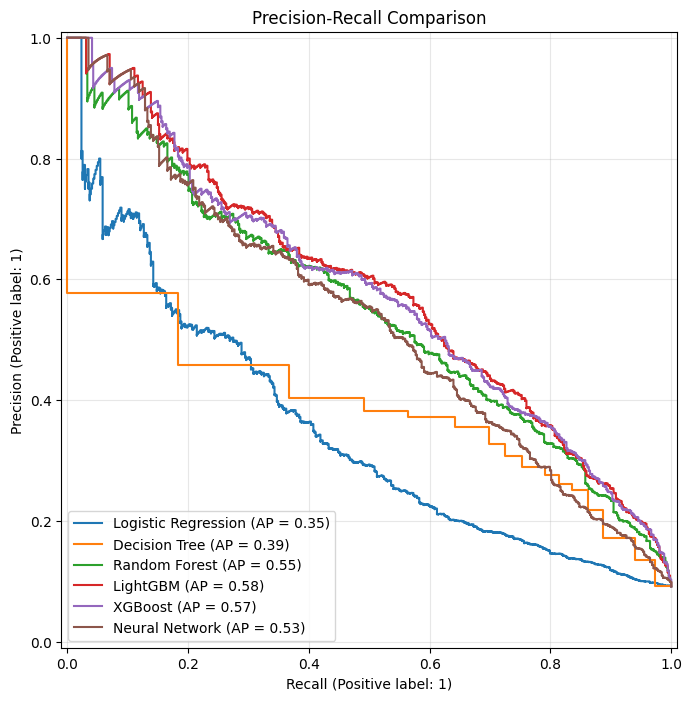

In [29]:
plt.figure(figsize=(10, 8))

for name, pred in predictions.items():

    PrecisionRecallDisplay.from_predictions(
        y_val,
        pred,
        name=name,
        ax=plt.gca()
    )

plt.title("Precision-Recall Comparison")
plt.grid(alpha=0.3)
plt.show()

In [30]:
best_model_name = results_df.iloc[0]["Model"]

best_model = models[best_model_name]

print("Best validation model:", best_model_name)
print("Best ROC-AUC:", results_df.iloc[0]["ROC_AUC"])

Best validation model: LightGBM
Best ROC-AUC: 0.9068929668600657


In [31]:
rng = np.random.RandomState(RANDOM_STATE)

sample_indices = rng.choice(
    X_val_processed.shape[0],
    size=min(2000, X_val_processed.shape[0]),
    replace=False
)

X_perm = X_val_processed[sample_indices]
y_perm = y_val.iloc[sample_indices]

perm_result = permutation_importance(
    best_model,
    X_perm,
    y_perm,
    scoring="roc_auc",
    n_repeats=5,
    random_state=RANDOM_STATE,
    n_jobs=-1
)

feature_names = preprocessor.get_feature_names_out()

importance_df = pd.DataFrame({

    "Feature": feature_names,

    "Importance": perm_result.importances_mean,

    "Std": perm_result.importances_std

}).sort_values(
    by="Importance",
    ascending=False
)

display(importance_df.head(20))

,Feature,Importance,Std
21,num__CREDIT_INCOME_RATIO,0.070774,0.005021
12,num__EXT_SOURCE_3,0.042483,0.005282
11,num__EXT_SOURCE_2,0.036013,0.004822
22,num__ANNUITY_INCOME_RATIO,0.018721,0.002799
10,num__EXT_SOURCE_1,0.007984,0.001639
17,num__INSTAL_LATE_PAYMENT_RATIO,0.003156,0.001096
4,num__DAYS_EMPLOYED,0.003116,0.000842
30,cat__CODE_GENDER_F,0.000934,0.000484
8,num__AMT_GOODS_PRICE,0.000629,0.000334
3,num__DAYS_BIRTH,0.000505,0.001559


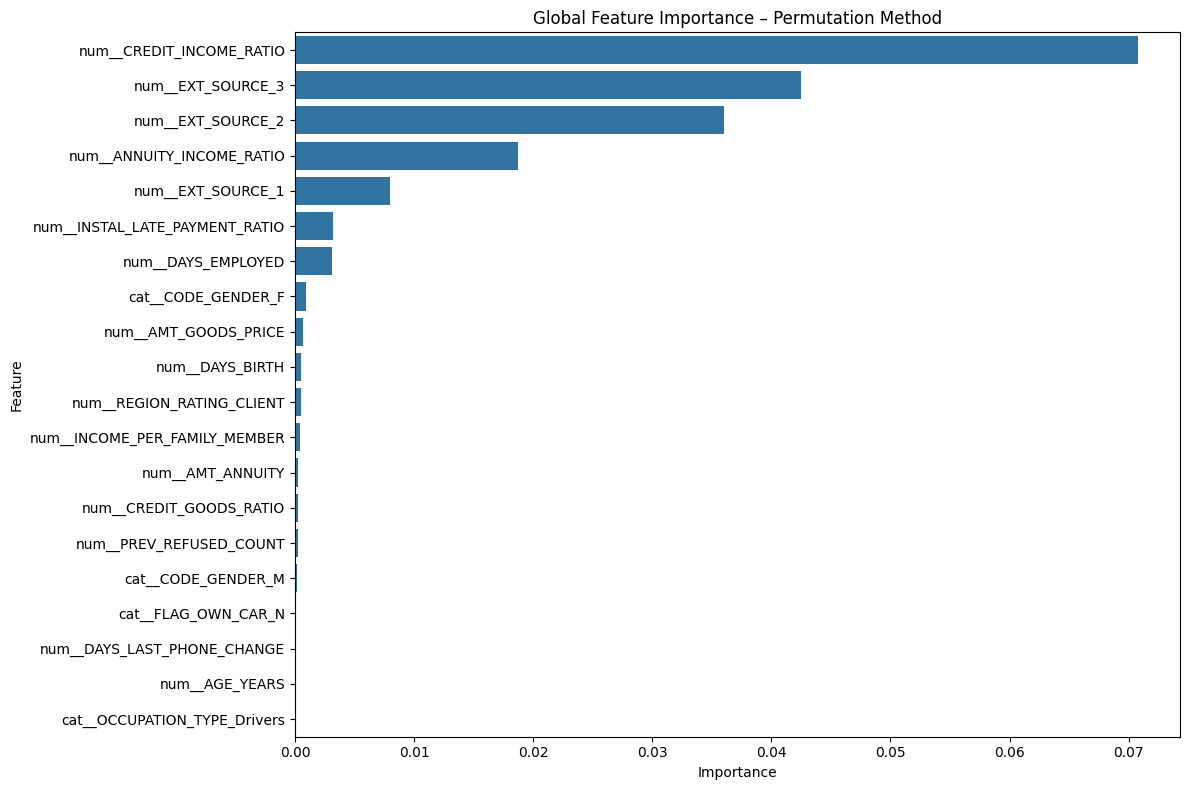

In [32]:
plt.figure(figsize=(12, 8))

top_features = importance_df.head(20)

sns.barplot(
    data=top_features,
    x="Importance",
    y="Feature"
)

plt.title("Global Feature Importance – Permutation Method")
plt.tight_layout()
plt.show()

In [33]:
explainer = shap.TreeExplainer(
    lightgbm_model
)

shap_sample = X_val_processed[:1000]

if hasattr(shap_sample, "toarray"):
    shap_sample_dense = shap_sample.toarray()
else:
    shap_sample_dense = np.asarray(shap_sample)

shap_values = explainer.shap_values(
    shap_sample_dense
)

if isinstance(shap_values, list):
    shap_values = shap_values[1]

elif len(shap_values.shape) == 3:
    shap_values = shap_values[:, :, 1]

print("SHAP analysis completed")

SHAP analysis completed


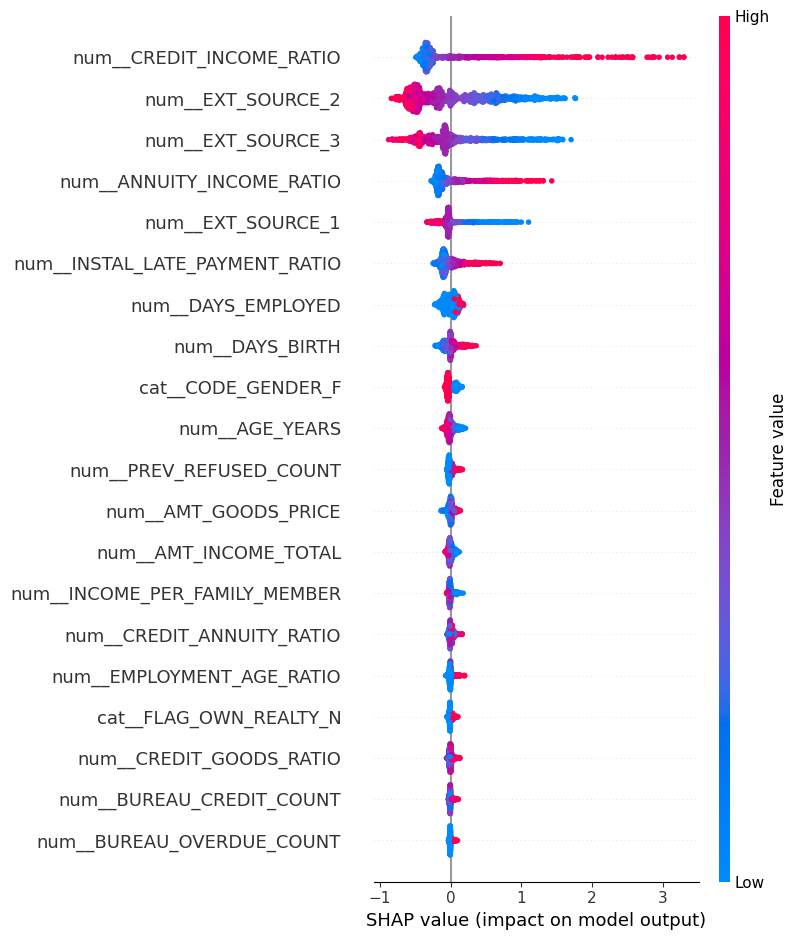

In [34]:
shap.summary_plot(
    shap_values,
    shap_sample_dense,
    feature_names=feature_names,
    max_display=20
)

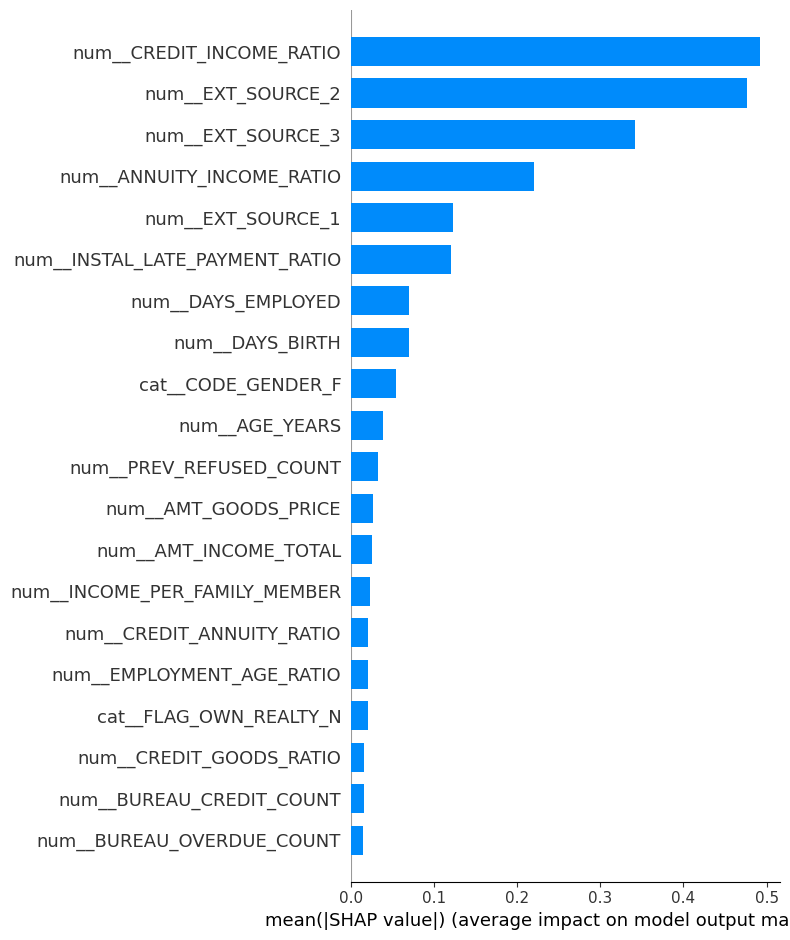

In [35]:
shap.summary_plot(
    shap_values,
    shap_sample_dense,
    feature_names=feature_names,
    plot_type="bar",
    max_display=20
)

In [36]:
mean_shap = np.abs(shap_values).mean(axis=0)

shap_importance = pd.DataFrame({

    "Feature": feature_names,

    "Mean_Absolute_SHAP": mean_shap

}).sort_values(
    "Mean_Absolute_SHAP",
    ascending=False
)

display(shap_importance.head(20))

,Feature,Mean_Absolute_SHAP
21,num__CREDIT_INCOME_RATIO,0.491532
11,num__EXT_SOURCE_2,0.475926
12,num__EXT_SOURCE_3,0.341575
22,num__ANNUITY_INCOME_RATIO,0.220445
10,num__EXT_SOURCE_1,0.122667
17,num__INSTAL_LATE_PAYMENT_RATIO,0.120926
4,num__DAYS_EMPLOYED,0.069841
3,num__DAYS_BIRTH,0.069748
30,cat__CODE_GENDER_F,0.053576
20,num__AGE_YEARS,0.039034


In [38]:
customer_index = 0

customer = shap_sample_dense[customer_index]

# Slicing with [index : index+1] keeps the array 2D, preventing the ValueError
customer_prediction = lightgbm_model.predict_proba(
    shap_sample[customer_index : customer_index + 1]
)[0, 1]

print("Customer default probability:",
      round(customer_prediction * 100, 2), "%")

print("Predicted class:",
      "Potential Default" if customer_prediction >= 0.5
      else "No Default Prediction")

Customer default probability: 1.44 %
Predicted class: No Default Prediction


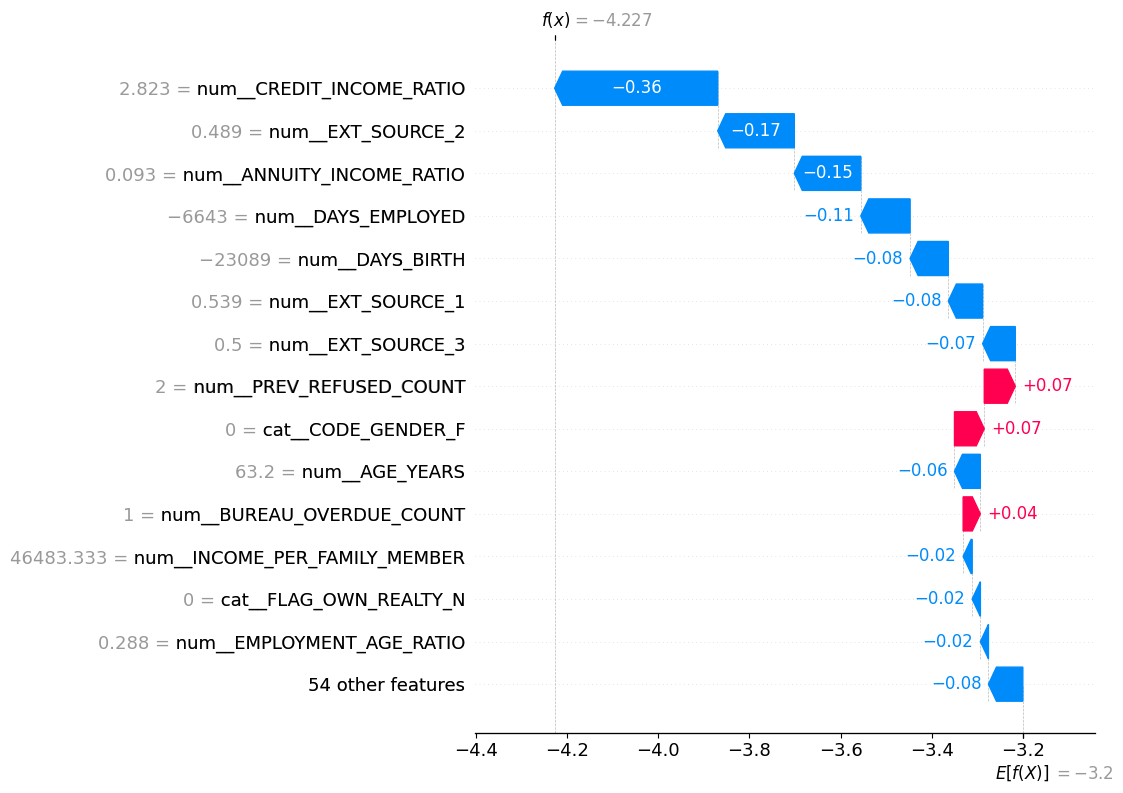

In [39]:
base_value = explainer.expected_value

if isinstance(base_value, (list, np.ndarray)):
    base_value = np.asarray(base_value).flatten()[-1]

local_explanation = shap.Explanation(
    values=shap_values[customer_index],
    base_values=base_value,
    data=customer,
    feature_names=feature_names
)

shap.plots.waterfall(
    local_explanation,
    max_display=15
)

In [40]:
customer_raw = X_val.iloc[[customer_index]].copy()

def predict_customer_probability(data):

    processed = preprocessor.transform(data)

    return lightgbm_model.predict_proba(
        processed
    )[:, 1]


print(
    "Original probability:",
    predict_customer_probability(customer_raw)[0]
)

feature_to_change = "AMT_INCOME_TOTAL"

if feature_to_change in customer_raw.columns:

    original_value = customer_raw[
        feature_to_change
    ].iloc[0]

    for factor in [0.8, 1.0, 1.2, 1.5]:

        modified = customer_raw.copy()

        modified[feature_to_change] = (
            original_value * factor
        )

        probability = predict_customer_probability(
            modified
        )[0]

        print(
            f"{factor}x income:",
            round(probability * 100, 2),
            "%"
        )

Original probability: 0.01437938929816968
0.8x income: 1.49 %
1.0x income: 1.44 %
1.2x income: 1.43 %
1.5x income: 1.43 %


Selected features: ['num__CNT_CHILDREN', 'num__CNT_FAM_MEMBERS', 'num__REGION_RATING_CLIENT']


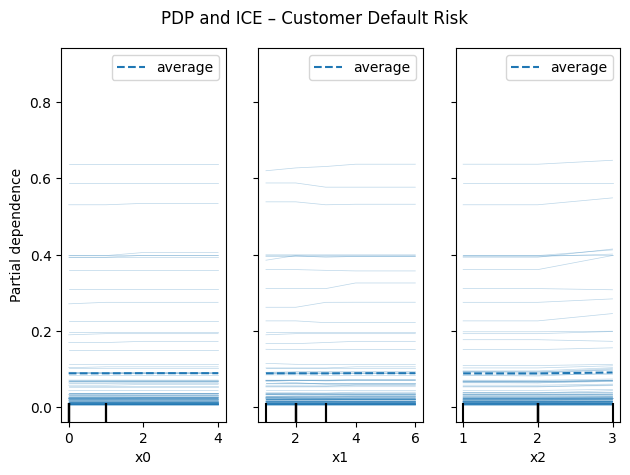

In [41]:
numeric_feature_indices = [
    i for i, name in enumerate(feature_names)
    if name.startswith("num__")
]

top_numeric_features = [
    i for i in numeric_feature_indices
    if feature_names[i] in shap_importance.head(50)["Feature"].values
][:3]

print(
    "Selected features:",
    [feature_names[i] for i in top_numeric_features]
)

PartialDependenceDisplay.from_estimator(
    lightgbm_model,
    X_val_processed,
    features=top_numeric_features,
    kind="both",
    subsample=100,
    grid_resolution=20,
    random_state=RANDOM_STATE
)

plt.suptitle("PDP and ICE – Customer Default Risk")
plt.tight_layout()
plt.show()

INFO:PyALE._ALE_generic:Continuous feature detected.


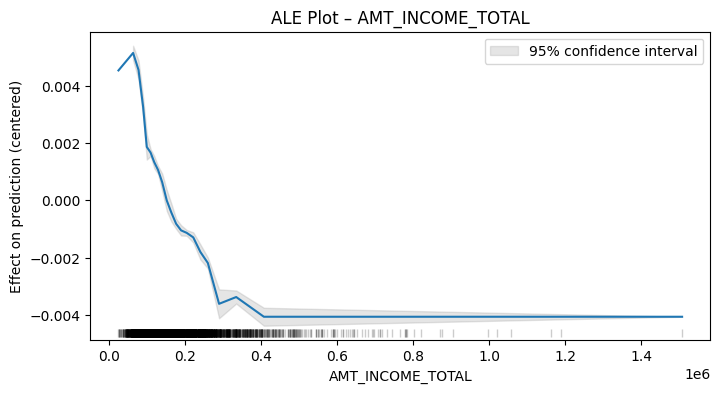

INFO:PyALE._ALE_generic:Continuous feature detected.


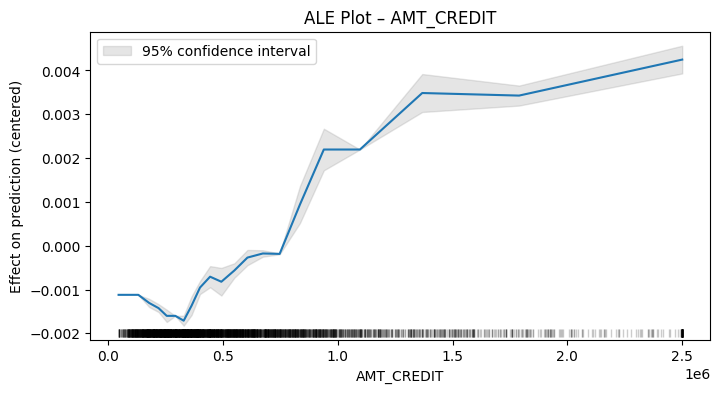

INFO:PyALE._ALE_generic:Continuous feature detected.


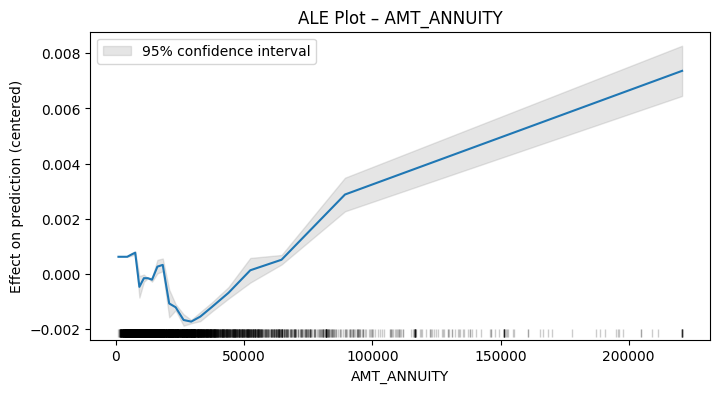

In [43]:
from PyALE import ale

class RawDataPredictor:
    def predict(self, X):
        transformed = preprocessor.transform(X)
        return lightgbm_model.predict_proba(transformed)[:, 1]

raw_predictor = RawDataPredictor()

ale_features = [
    col for col in [
        "AMT_INCOME_TOTAL",
        "AMT_CREDIT",
        "AMT_ANNUITY",
        "DAYS_BIRTH",
        "DAYS_EMPLOYED"
    ]
    if col in X_val.columns
]

# We sample the entire rows from X_val (all 37 columns) instead of just the 5 features
ale_sample = X_val.sample(
    n=min(3000, len(X_val)),
    random_state=RANDOM_STATE
)

for feature in ale_features[:3]:
    ale(
        X=ale_sample,
        model=raw_predictor,
        feature=[feature],
        include_CI=True
    )
    plt.title(f"ALE Plot – {feature}")
    plt.show()

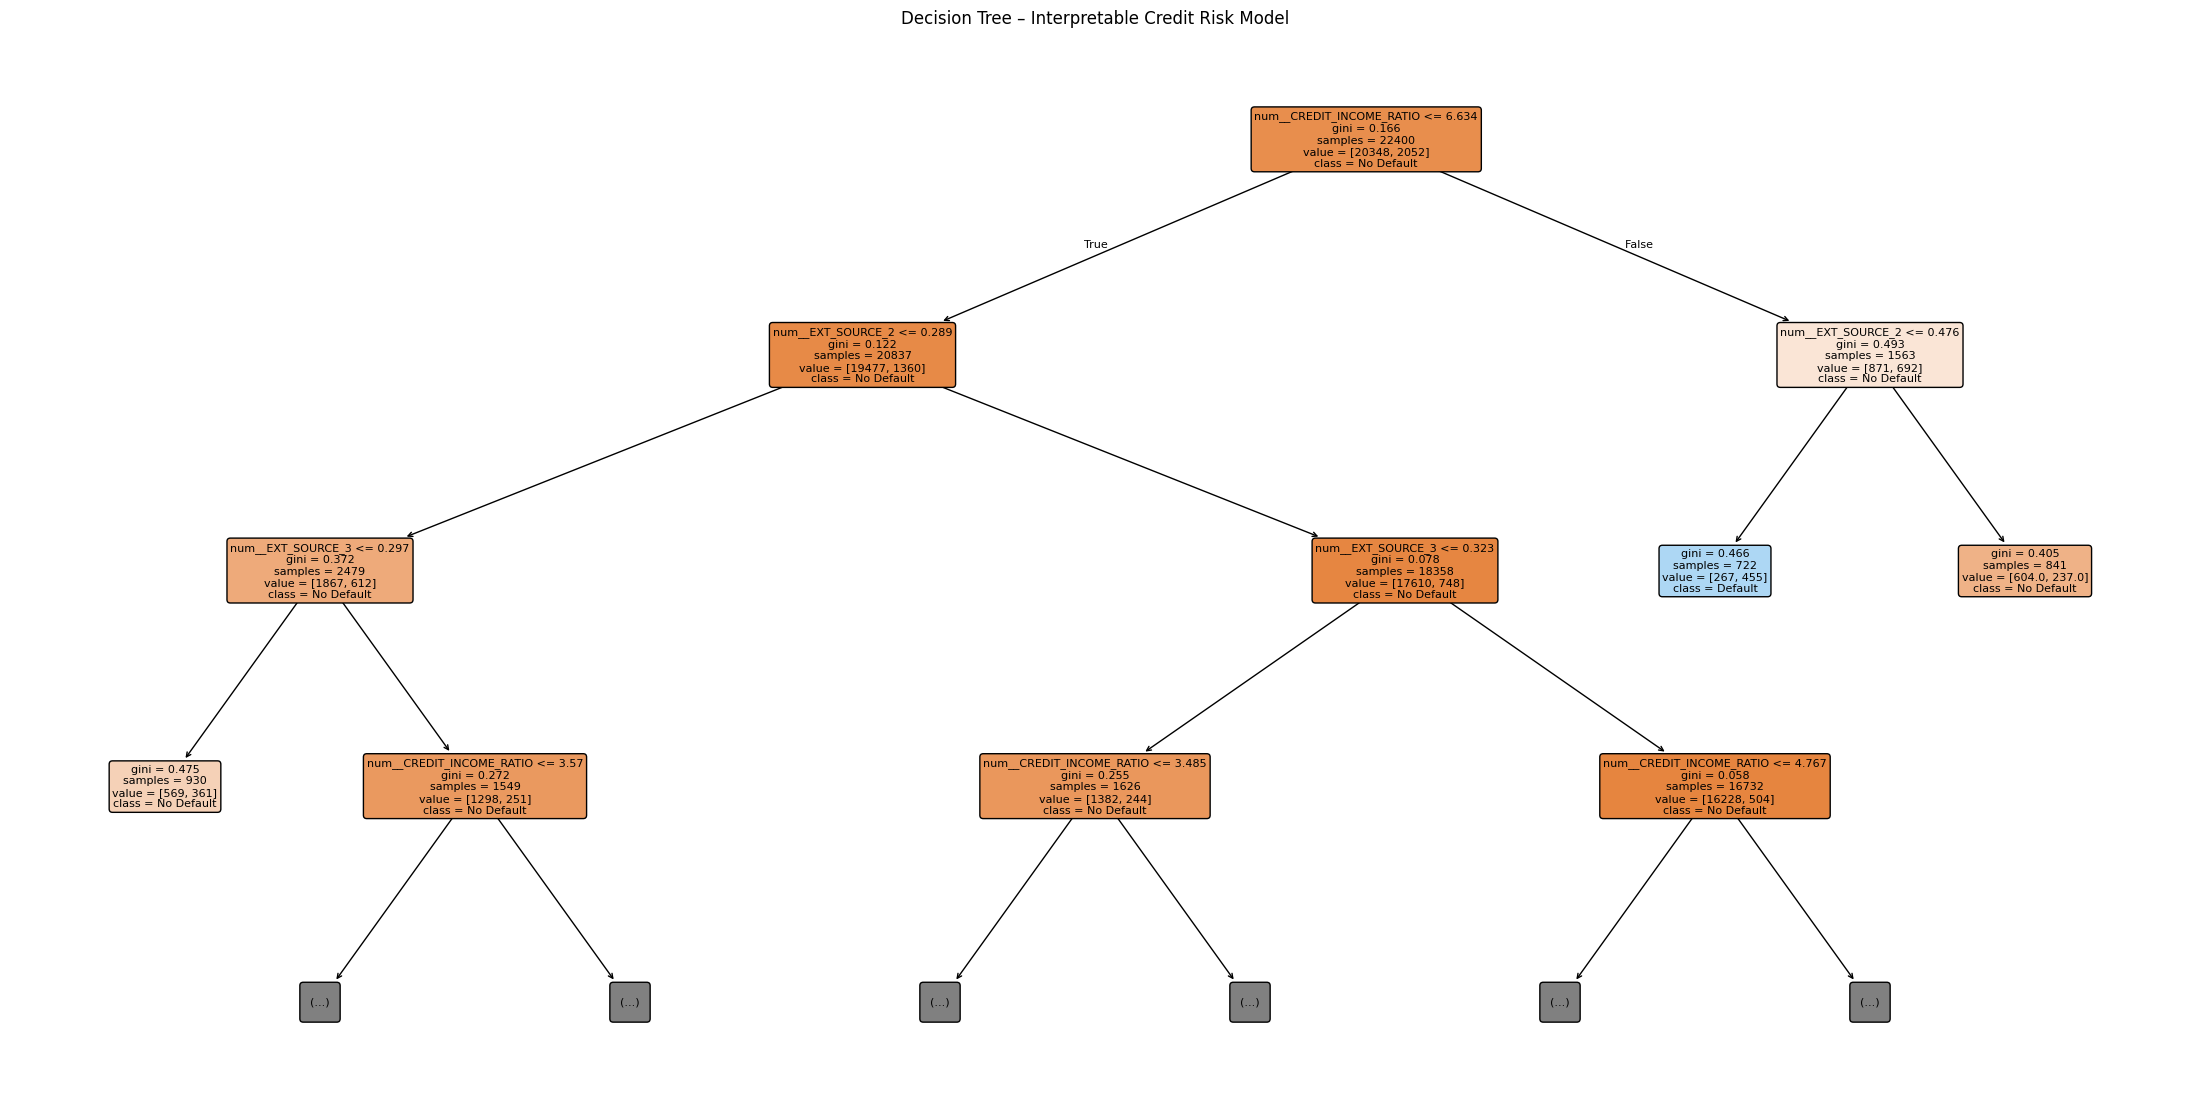

In [44]:
from sklearn.tree import plot_tree

plt.figure(figsize=(28, 14))

plot_tree(
    decision_tree,
    max_depth=3,
    feature_names=feature_names,
    class_names=[
        "No Default",
        "Default"
    ],
    filled=True,
    rounded=True,
    fontsize=8
)

plt.title("Decision Tree – Interpretable Credit Risk Model")

plt.show()

Optimal F1 threshold: 0.2899999999999999


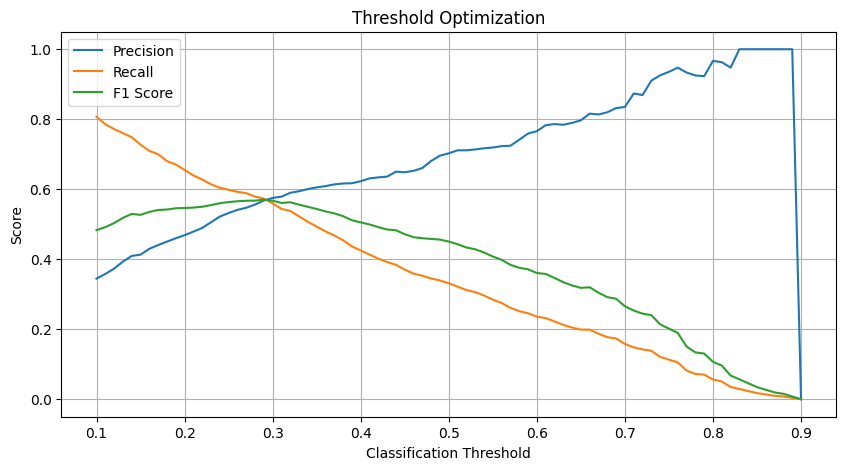

In [45]:
best_prediction = predictions[best_model_name]

thresholds = np.arange(0.10, 0.91, 0.01)

threshold_results = []

for threshold in thresholds:

    pred_class = (
        best_prediction >= threshold
    ).astype(int)

    threshold_results.append({

        "Threshold": threshold,

        "Precision": precision_score(
            y_val,
            pred_class,
            zero_division=0
        ),

        "Recall": recall_score(
            y_val,
            pred_class,
            zero_division=0
        ),

        "F1": f1_score(
            y_val,
            pred_class,
            zero_division=0
        )
    })

threshold_df = pd.DataFrame(threshold_results)

optimal_threshold = threshold_df.loc[
    threshold_df["F1"].idxmax(),
    "Threshold"
]

print("Optimal F1 threshold:", optimal_threshold)

plt.figure(figsize=(10, 5))

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Precision"],
    label="Precision"
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Recall"],
    label="Recall"
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["F1"],
    label="F1 Score"
)

plt.xlabel("Classification Threshold")
plt.ylabel("Score")
plt.title("Threshold Optimization")
plt.legend()
plt.grid()
plt.show()

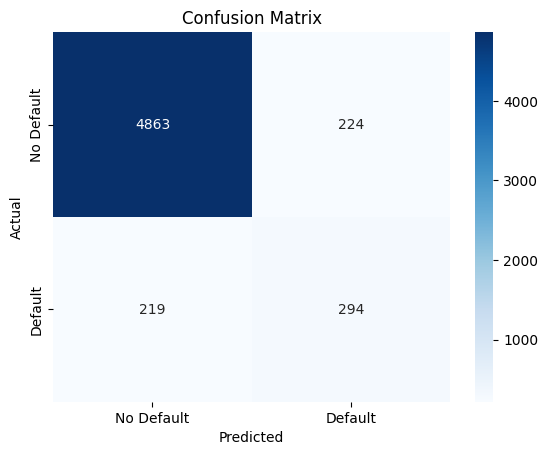

              precision    recall  f1-score   support

  No Default       0.96      0.96      0.96      5087
     Default       0.57      0.57      0.57       513

    accuracy                           0.92      5600
   macro avg       0.76      0.76      0.76      5600
weighted avg       0.92      0.92      0.92      5600



In [46]:
final_val_class = (
    best_prediction >= optimal_threshold
).astype(int)

cm = confusion_matrix(
    y_val,
    final_val_class
)

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Default", "Default"],
    yticklabels=["No Default", "Default"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

print(
    classification_report(
        y_val,
        final_val_class,
        target_names=["No Default", "Default"]
    )
)

In [47]:
preprocessor_full = clone(preprocessor)

X_full_processed = preprocessor_full.fit_transform(X)

X_test_final = preprocessor_full.transform(X_test)

final_svd = None
final_scaler = None

if best_model_name == "Neural Network":

    final_svd = TruncatedSVD(
        n_components=min(
            100,
            X_full_processed.shape[1] - 1
        ),
        random_state=RANDOM_STATE
    )

    full_svd = final_svd.fit_transform(
        X_full_processed
    )

    test_svd = final_svd.transform(
        X_test_final
    )

    final_scaler = StandardScaler()

    full_svd = final_scaler.fit_transform(full_svd)
    test_svd = final_scaler.transform(test_svd)

    final_model = clone(neural_network)

    final_model.fit(full_svd, y)

    test_probability = final_model.predict_proba(
        test_svd
    )[:, 1]

else:

    final_model = clone(best_model)

    if best_model_name == "LightGBM":

        final_iterations = getattr(
            lightgbm_model,
            "best_iteration_",
            0
        ) or 1000

        final_model.set_params(
            n_estimators=final_iterations
        )

    elif best_model_name == "XGBoost":

        final_iterations = getattr(
            xgboost_model,
            "best_iteration",
            0
        )

        final_model.set_params(
            n_estimators=final_iterations + 1,
            early_stopping_rounds=None
        )

    final_model.fit(
        X_full_processed,
        y
    )

    test_probability = final_model.predict_proba(
        X_test_final
    )[:, 1]

print("Final model:", best_model_name)
print("Final model trained successfully")

Final model: LightGBM
Final model trained successfully


In [48]:
submission = pd.DataFrame({

    "SK_ID_CURR": test["SK_ID_CURR"],

    "TARGET": test_probability

})

submission.to_csv(
    "/content/home_credit_submission.csv",
    index=False
)

display(submission.head())

print("Submission file created")

,SK_ID_CURR,TARGET
6826,106827,0.205831
20011,120012,0.361473
18010,118011,0.050869
28599,128600,0.148240
6879,106880,0.055181


Submission file created


In [49]:
import joblib

model_artifact = {
    "preprocessor": preprocessor_full,
    "model": final_model,
    "svd": final_svd,
    "scaler": final_scaler,
    "model_name": best_model_name,
    "threshold": float(optimal_threshold)
}

joblib.dump(
    model_artifact,
    "/content/home_credit_explainable_model.pkl"
)

print("Model saved successfully")

Model saved successfully


In [50]:
from google.colab import files

files.download(
    "/content/home_credit_submission.csv"
)

files.download(
    "/content/home_credit_explainable_model.pkl"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>